In [ ]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
import missingno as msno
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

In [ ]:
# df=pd.read_csv(r'C:\Users\World\Downloads\Compressed/clv_data.csv')
df=pd.read_csv(r'C:\Users\World\Downloads\synthetic_clv_training_data.csv')
print(df.info())
print(df.head())

In [ ]:
df.isna().sum()


['id', 'age', 'income', 'days_on_platform', 'visits', 'spending_score', 'purchases']


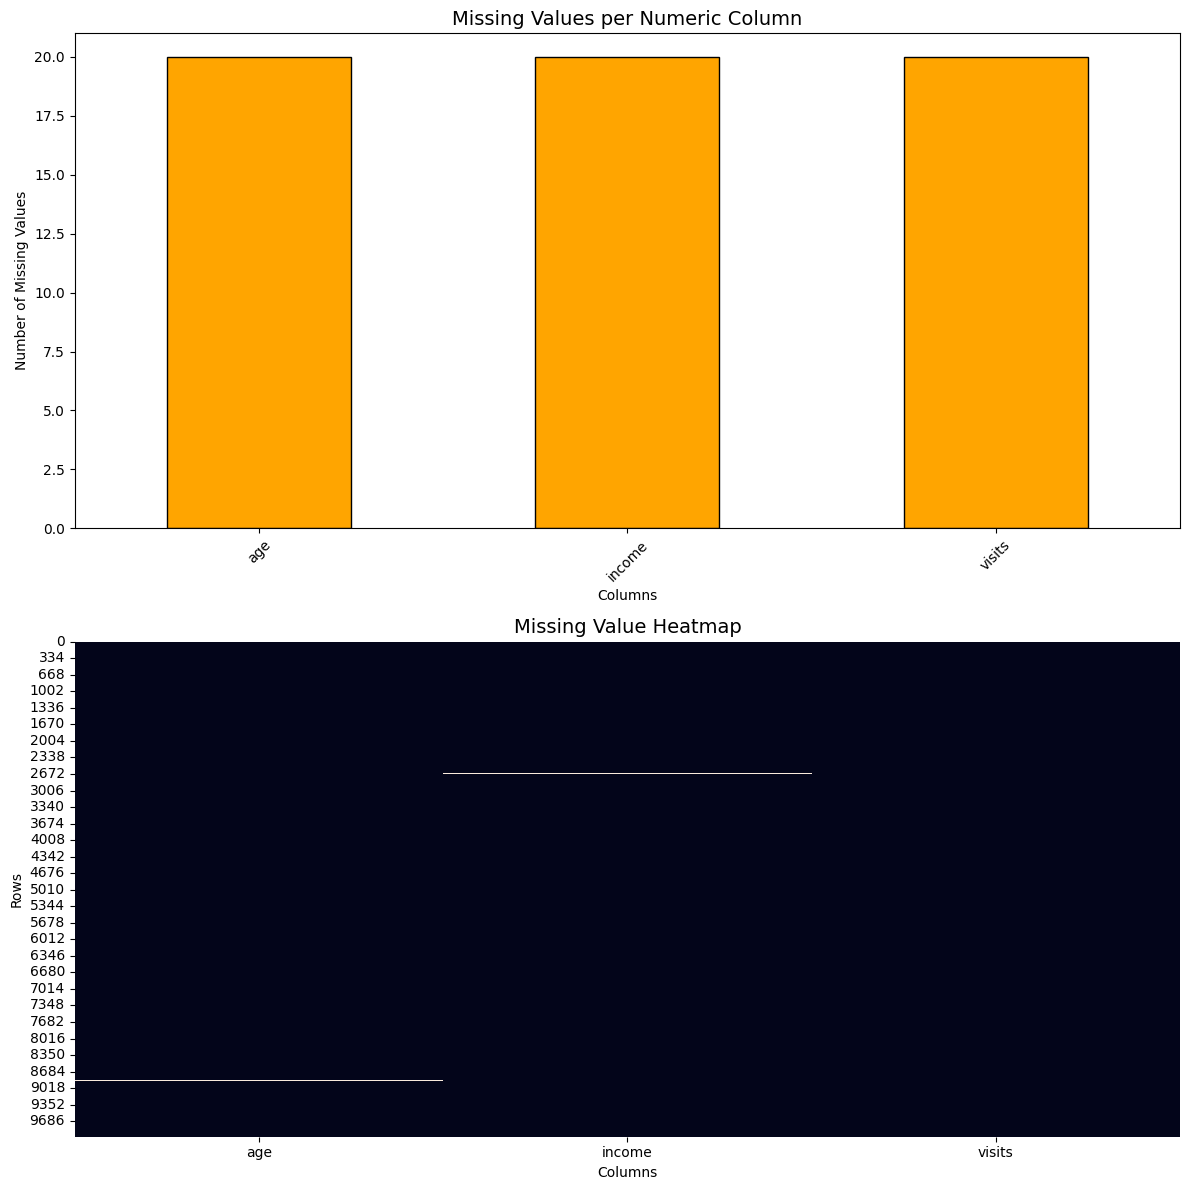

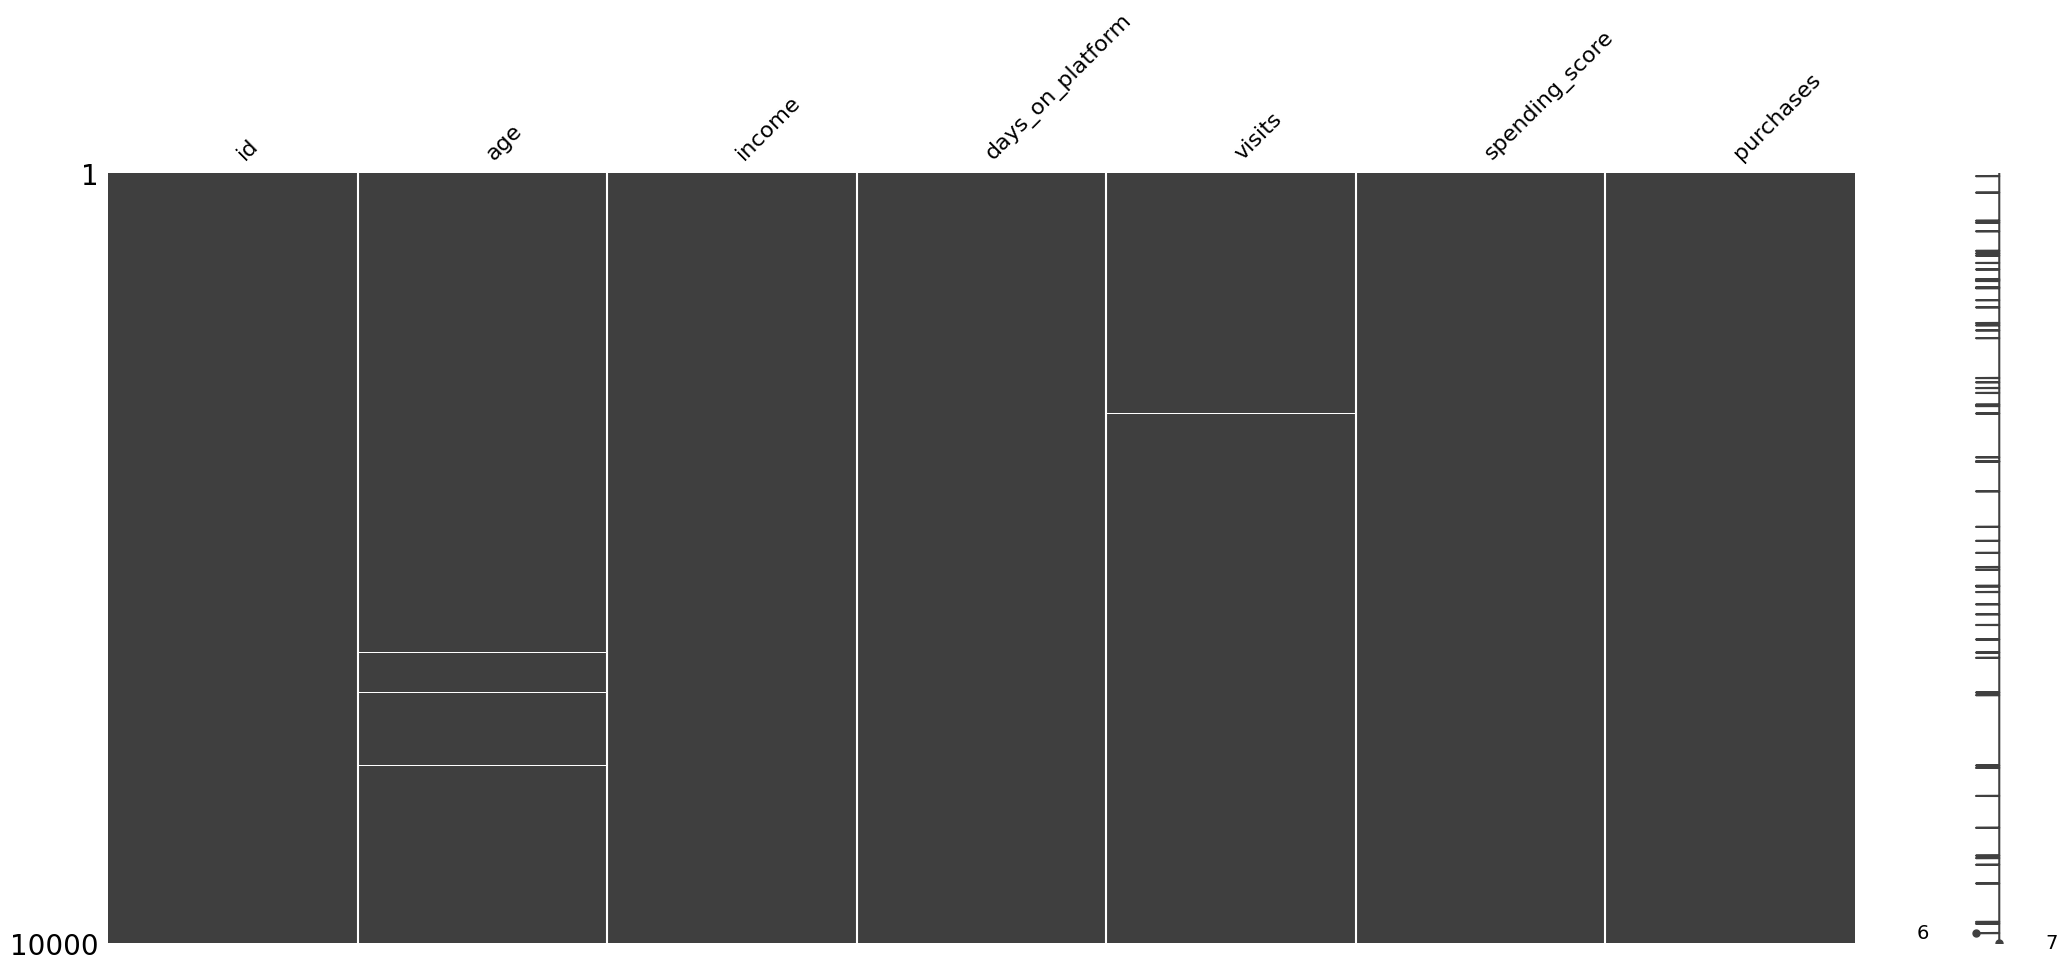

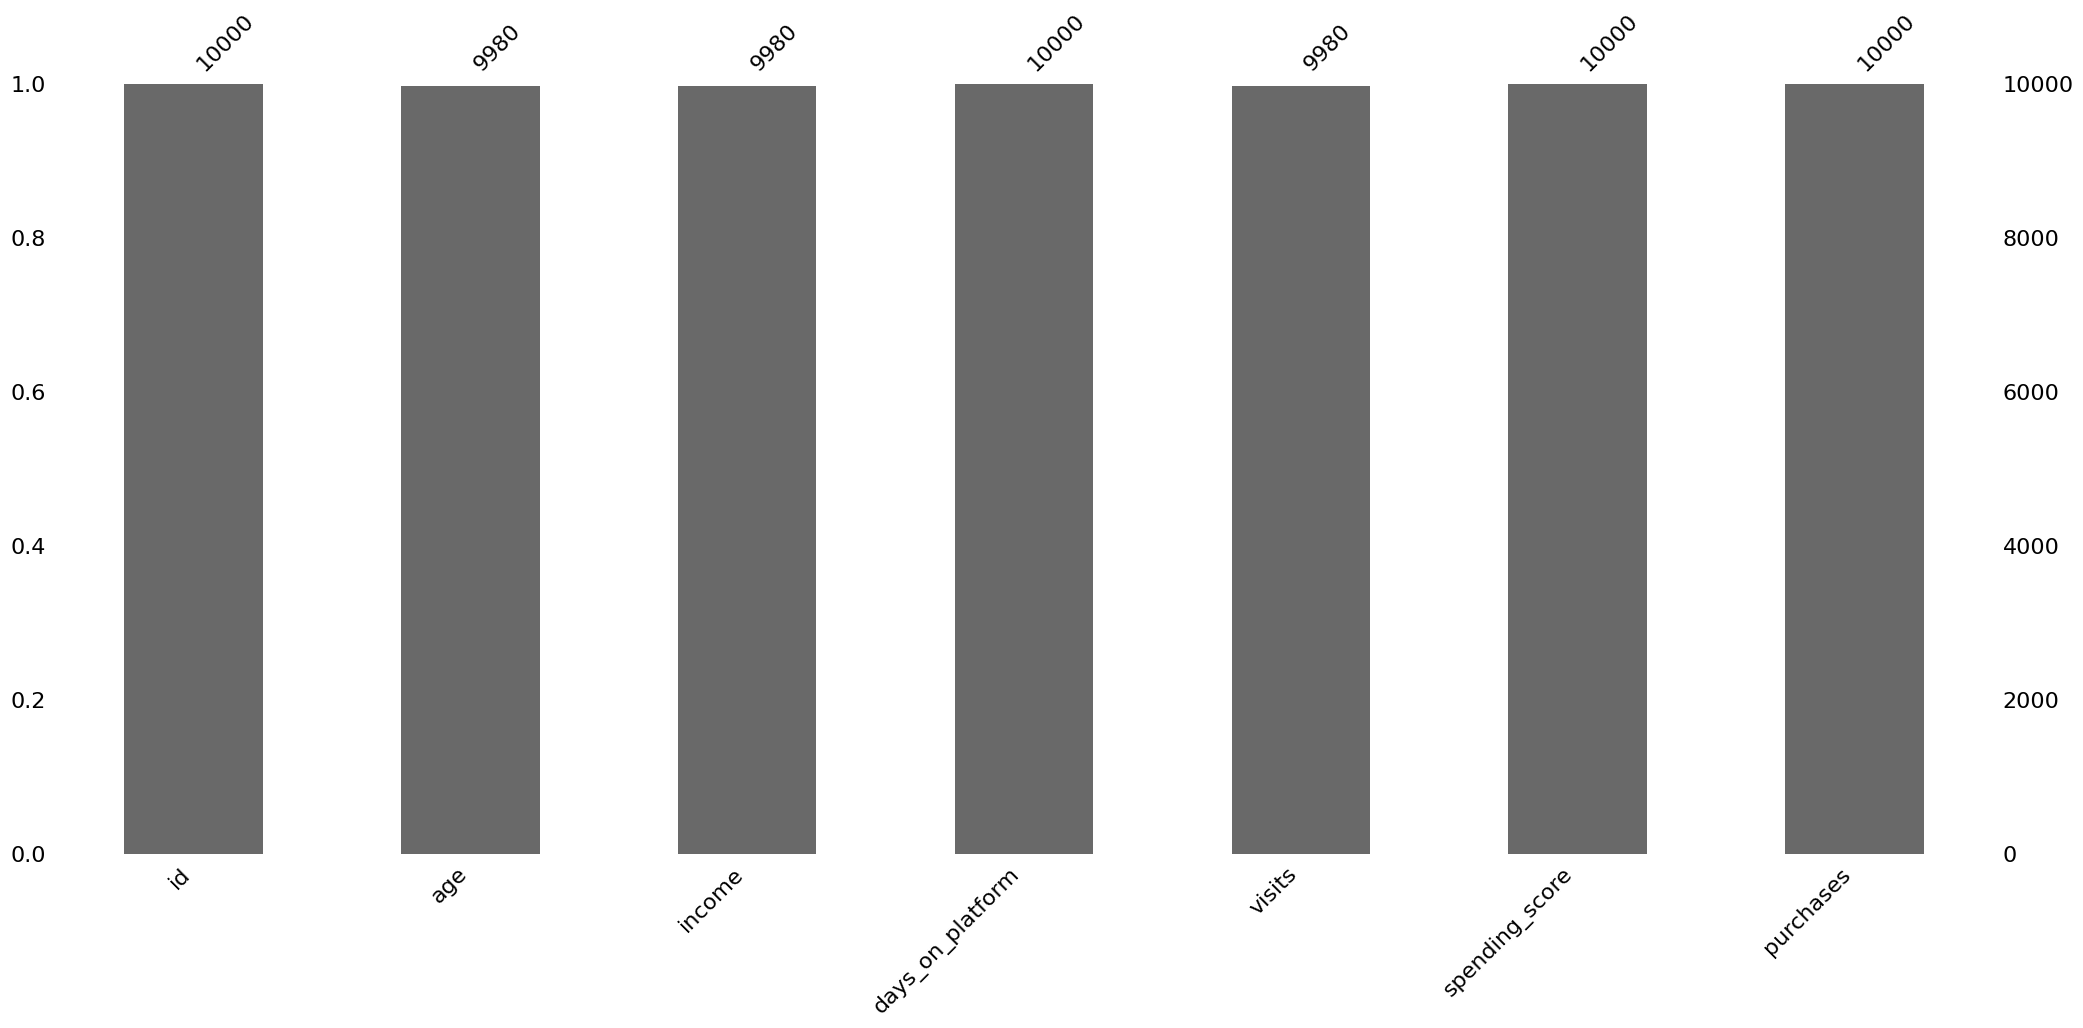

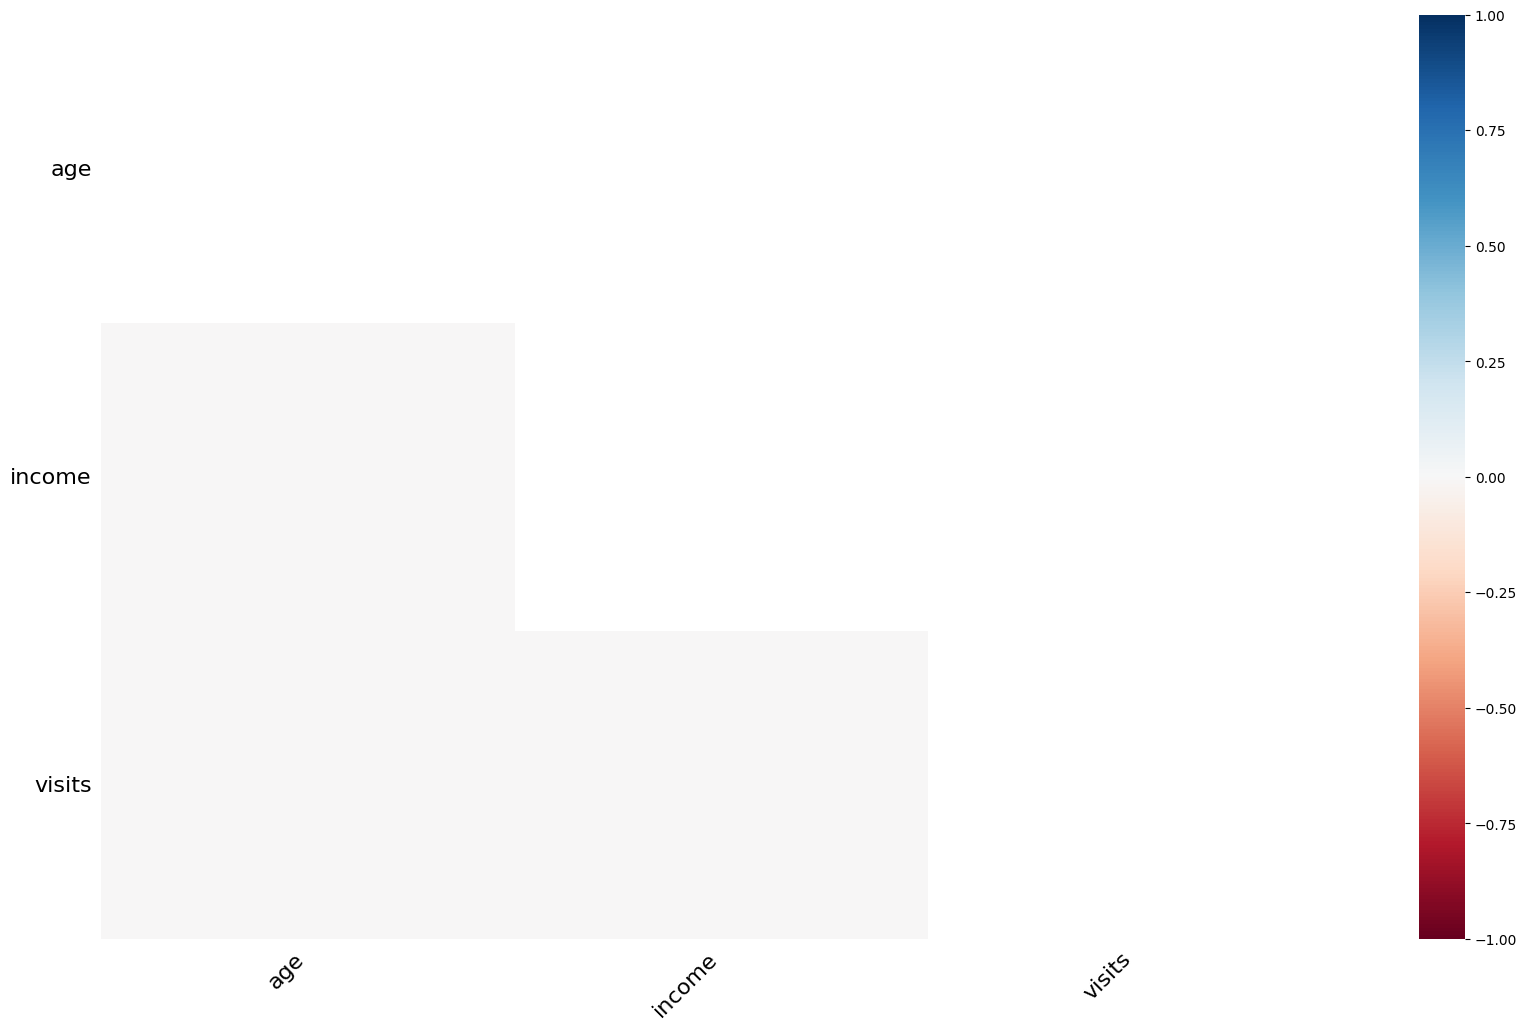

In [4]:
# 1. Get numeric columns
numeric_df = df.select_dtypes(include='number').columns.tolist()
# 2. Count missing values only for numeric columns
print(numeric_df)
missing_counts = df[numeric_df].isnull().sum()
missing_counts = missing_counts[missing_counts > 0]  # Keep only columns with missing values

if missing_counts.empty:
    print("✅ No missing values found in numeric columns.")
else:
    # ✅ Create a figure with 2 rows, 1 column (stacked)
    fig, axes = plt.subplots(2, 1, figsize=(12, 12))  # Taller figure for better readability

    # --- Subplot 1: Bar plot ---
    missing_counts.plot(kind='bar', color='orange', edgecolor='black', ax=axes[0])
    axes[0].set_title("Missing Values per Numeric Column", fontsize=14)
    axes[0].set_xlabel("Columns")
    axes[0].set_ylabel("Number of Missing Values")
    axes[0].tick_params(axis='x', rotation=45)

    # --- Subplot 2: Heatmap ---
    sns.heatmap(df[missing_counts.index].isnull(), cbar=False, ax=axes[1])
    axes[1].set_title("Missing Value Heatmap", fontsize=14)
    axes[1].set_xlabel("Columns")
    axes[1].set_ylabel("Rows")
    plt.tight_layout()
    plt.show()
    # --- Subplot 3: using lib missingno  ---
    # Matrix plot (visualizes patterns of missing data)
    msno.matrix(df)
    plt.show()
    # Bar plot
    msno.bar(df)
    plt.show()
    # Heatmap (which columns' missingness is correlated)
    msno.heatmap(df)
    plt.show()



In [5]:
for i in numeric_df:
    if df[i].isna().sum()>0:
        df[i]=df[i].fillna(df[i].mean())
    else:
        continue
df.isna().sum()        

id                  0
age                 0
income              0
days_on_platform    0
visits              0
spending_score      0
purchases           0
dtype: int64

<Axes: >

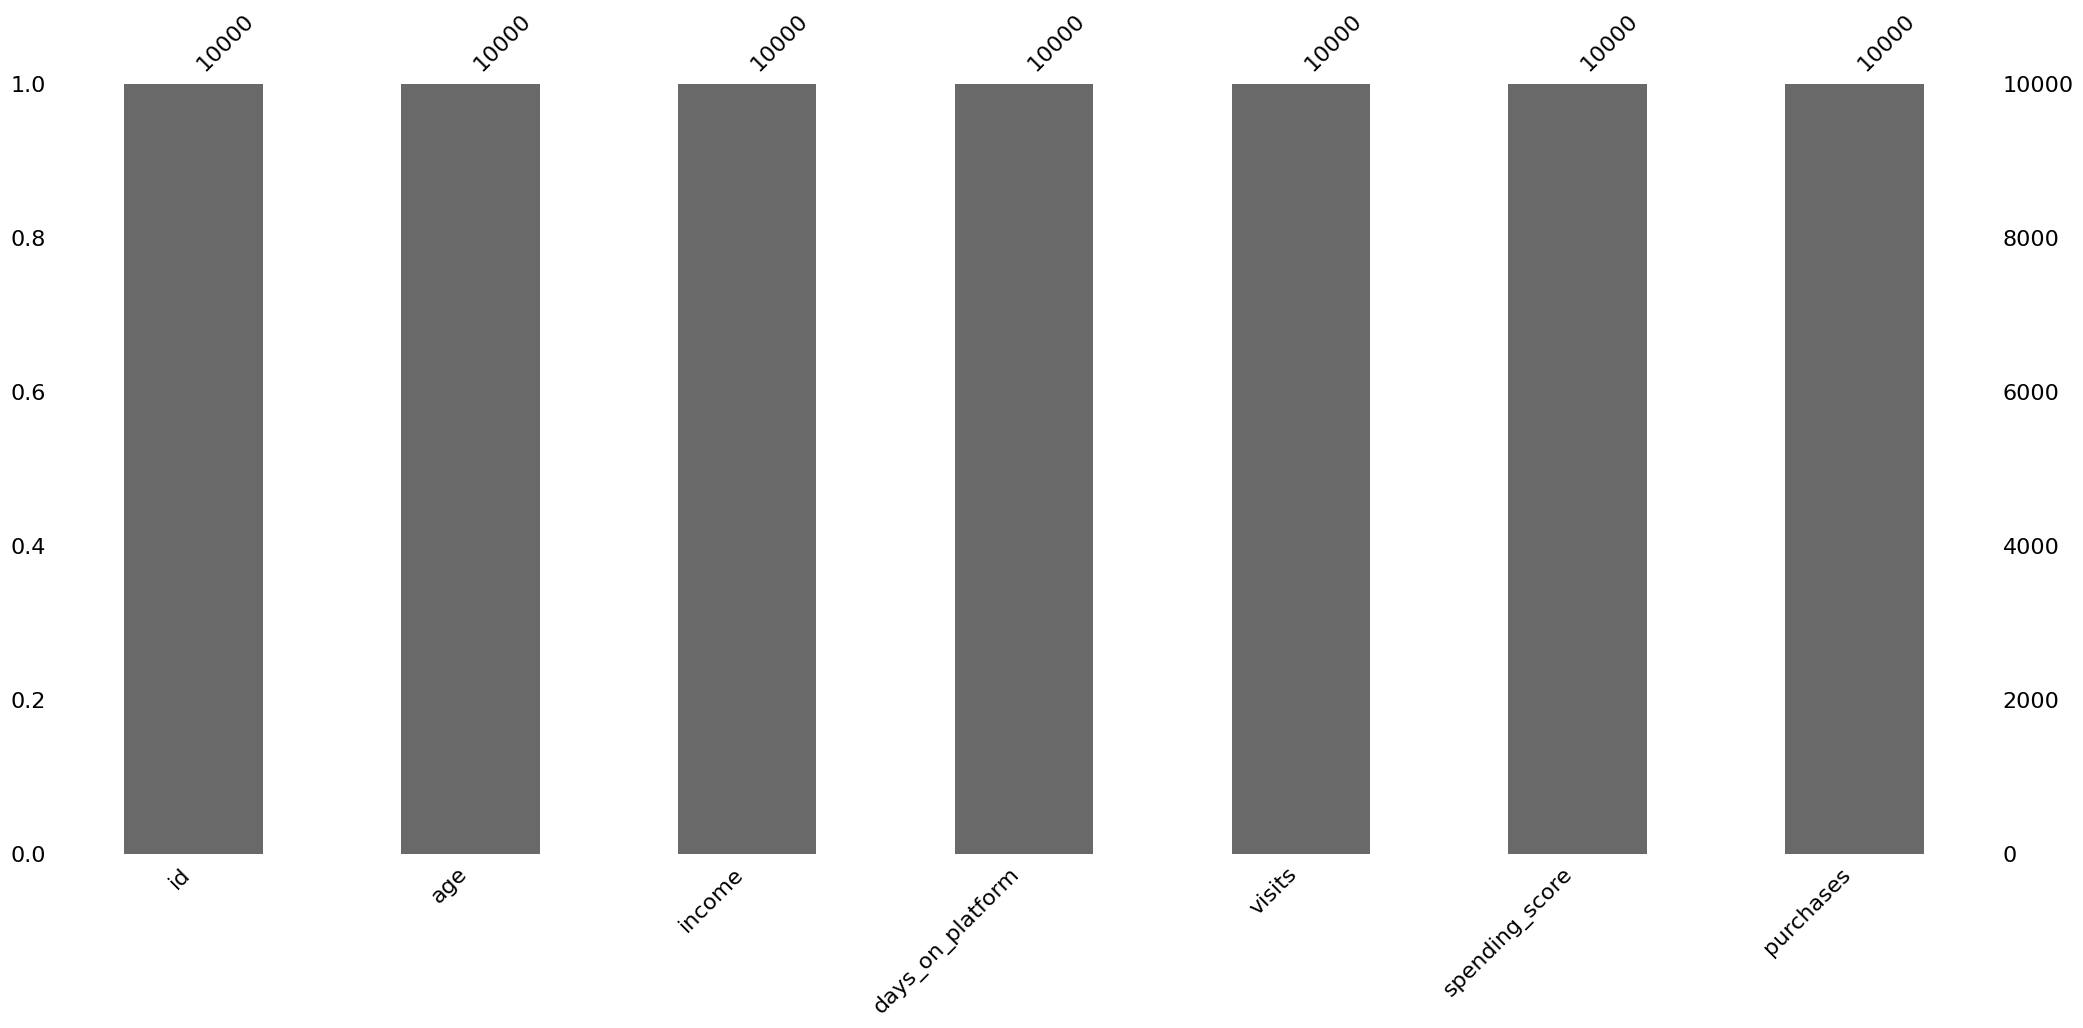

In [6]:
msno.bar(df)

(10000, 7)


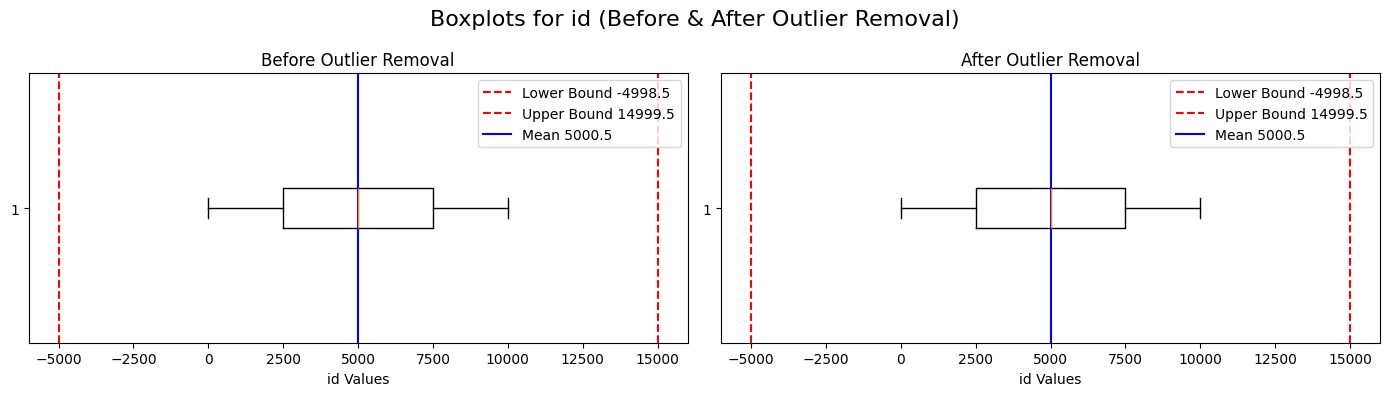

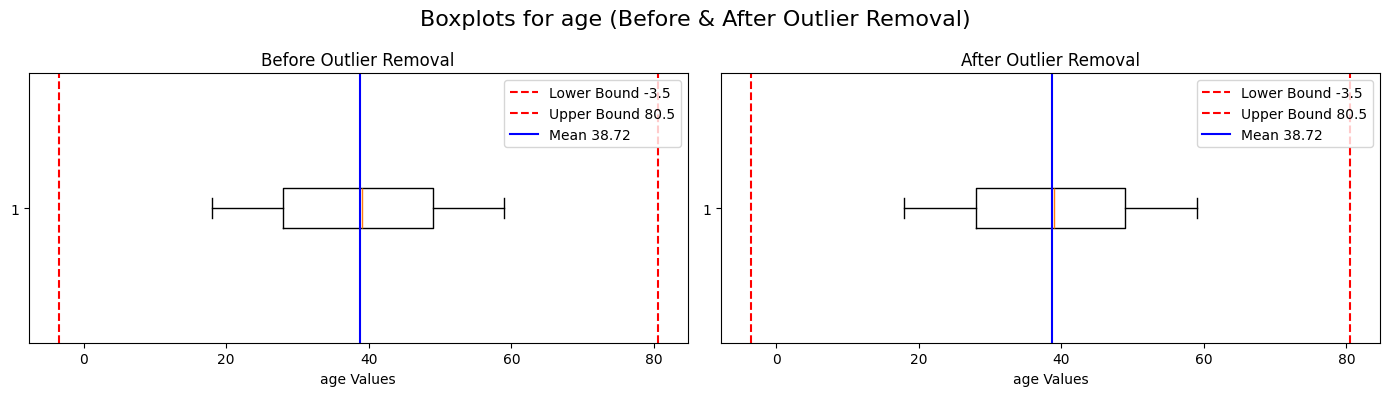

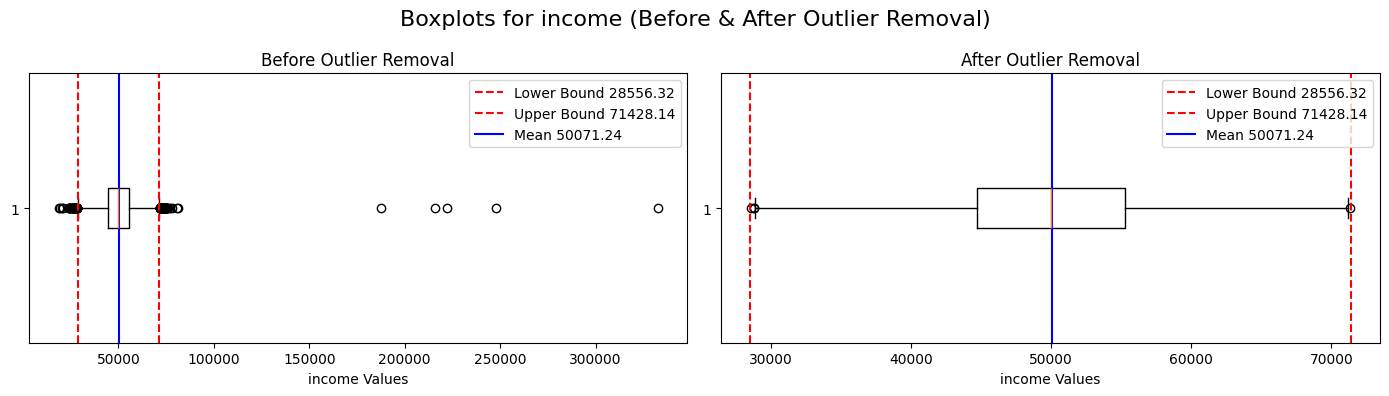

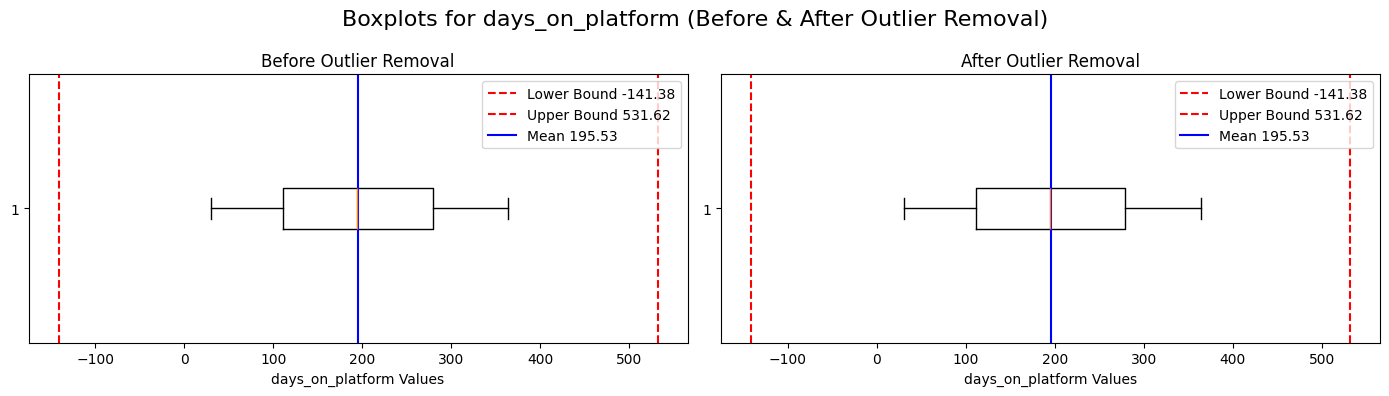

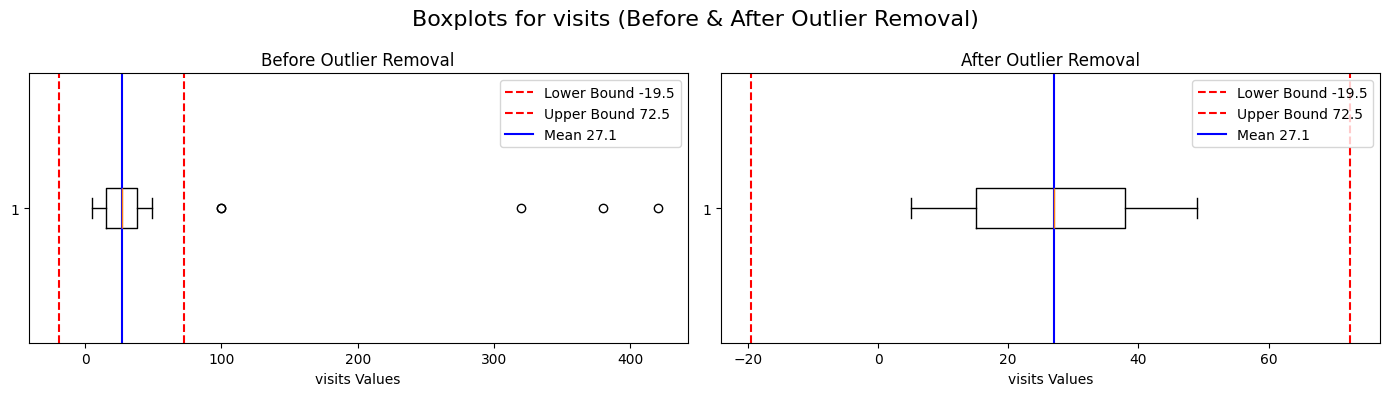

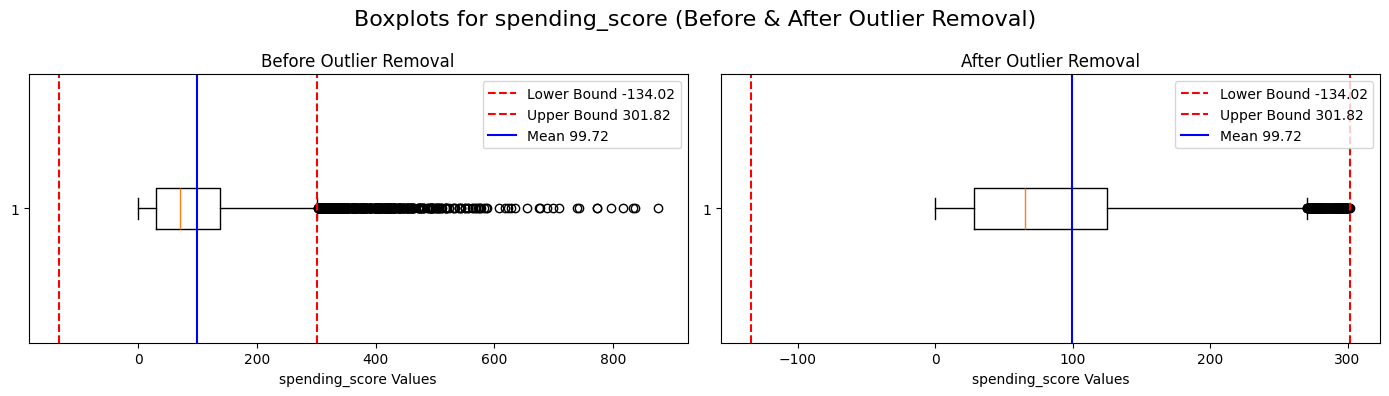

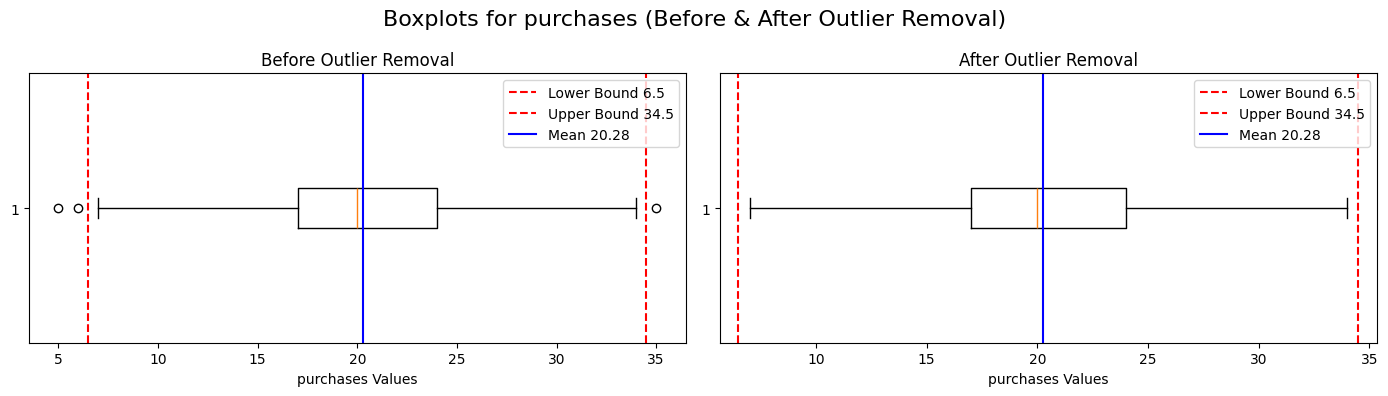

(9997, 7)


In [7]:
cols = df.columns
filtered_df=df
print(df.shape)
for col in cols:
    if np.issubdtype(df[col].dtype, np.number):  # Only numeric columns
        # Calculate statistics
        if df[col].dropna().empty:
            print(f"Skipping {col} (no data after previous filtering).")
            continue
        Q1 = np.percentile(df[col], 25)
        Q3 = np.percentile(df[col], 75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        mean_val = df[col].mean()

        # Create a figure with 2 subplots (1 row, 2 columns)
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))
        fig.suptitle(f"Boxplots for {col} (Before & After Outlier Removal)", fontsize=16)

        # --- BEFORE REMOVAL ---
        axes[0].boxplot(df[col], vert=False)
        axes[0].axvline(lower, color='red', linestyle='--', label=f'Lower Bound {lower.round(2)}')
        axes[0].axvline(upper, color='red', linestyle='--', label=f'Upper Bound {upper.round(2)}')
        axes[0].axvline(mean_val, color='blue', linestyle='-', label=f'Mean {mean_val.round(2)}')
        axes[0].set_title("Before Outlier Removal")
        axes[0].set_xlabel(f"{col} Values")
        axes[0].legend()

        # Remove outliers from df for next plot
        filtered_df = df[(df[col] > lower) & (df[col] < upper)]

        # --- AFTER REMOVAL ---
        axes[1].boxplot(filtered_df[col], vert=False)
        axes[1].axvline(lower, color='red', linestyle='--', label=f'Lower Bound {lower.round(2)}')
        axes[1].axvline(upper, color='red', linestyle='--', label=f'Upper Bound {upper.round(2)}')
        axes[1].axvline(mean_val, color='blue', linestyle='-', label=f'Mean {mean_val.round(2)}')
        axes[1].set_title("After Outlier Removal")
        axes[1].set_xlabel(f"{col} Values")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

        # Update df with outlier-free values for next iteration
df=filtered_df
print(df.shape)        


(9997, 7)


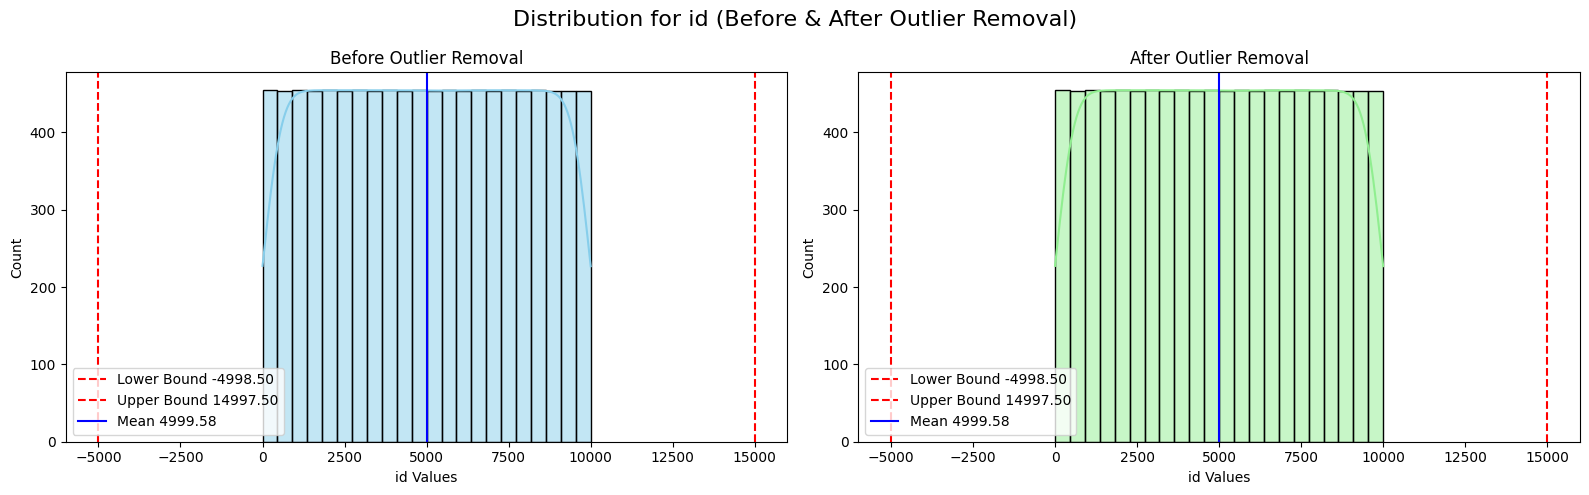

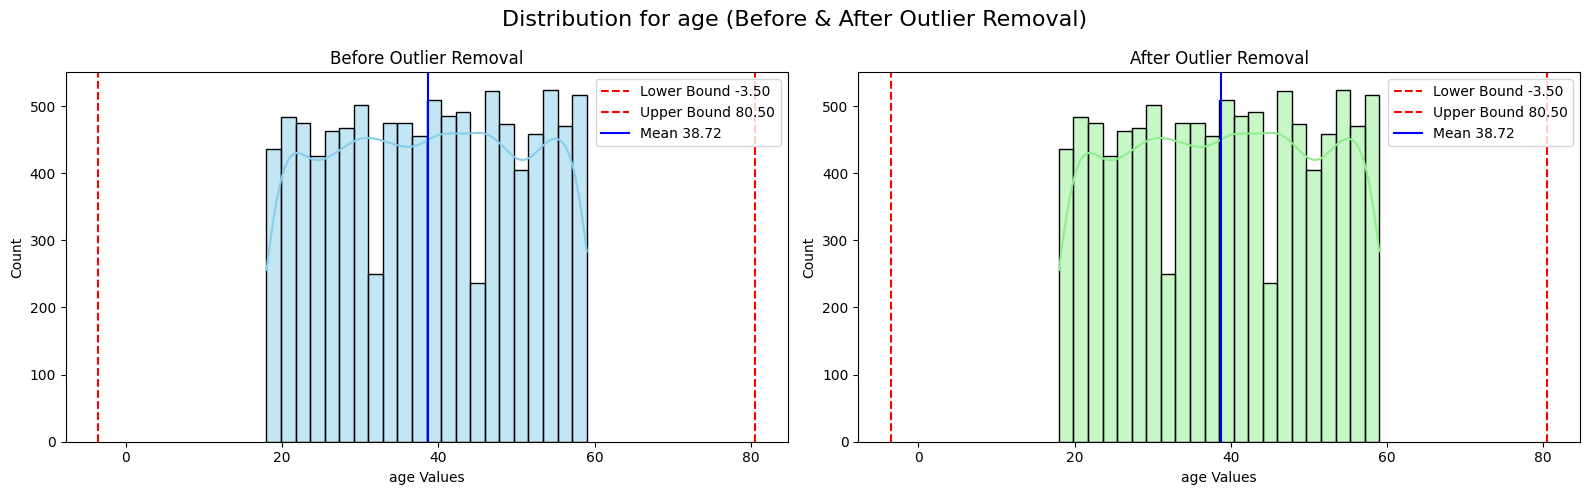

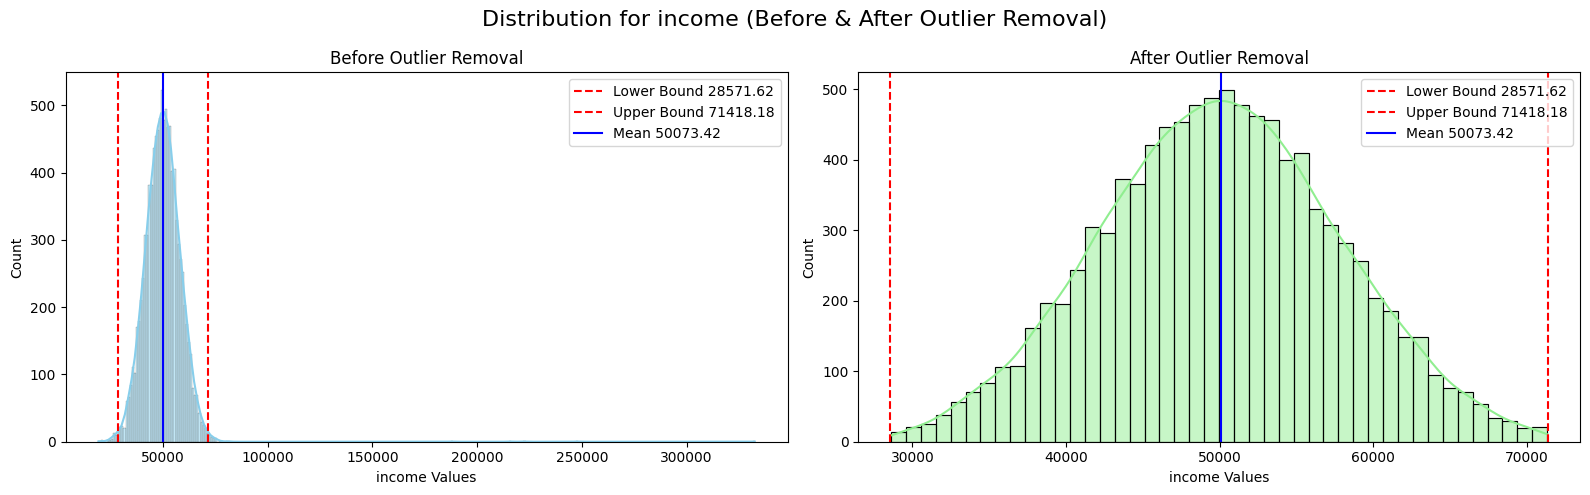

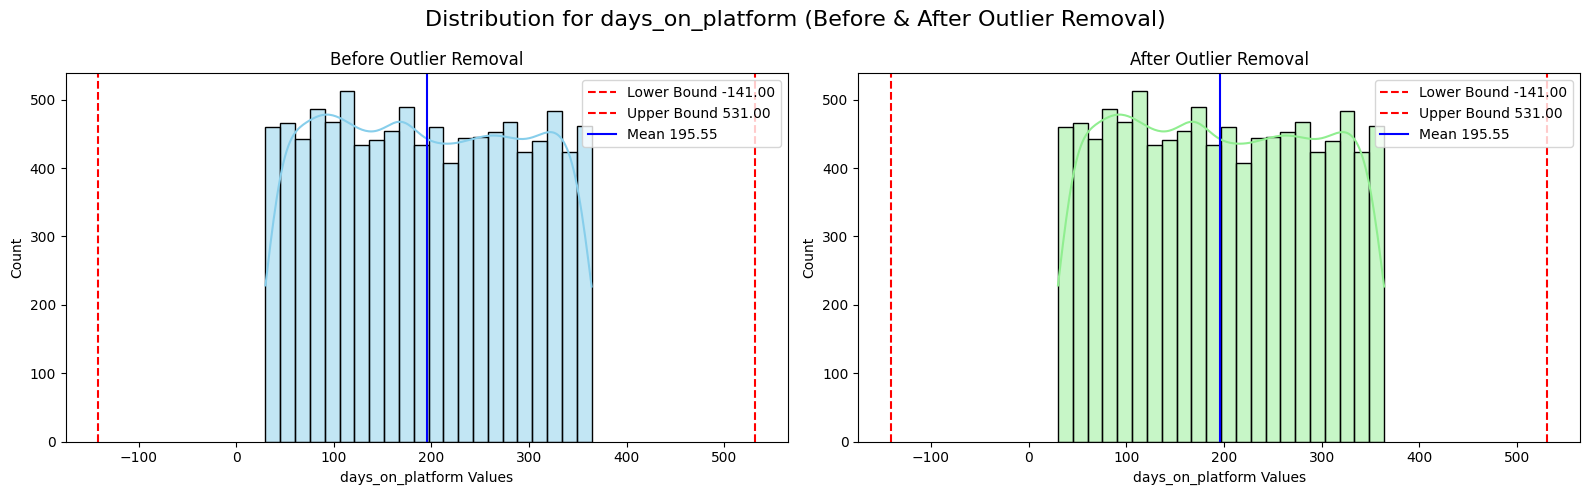

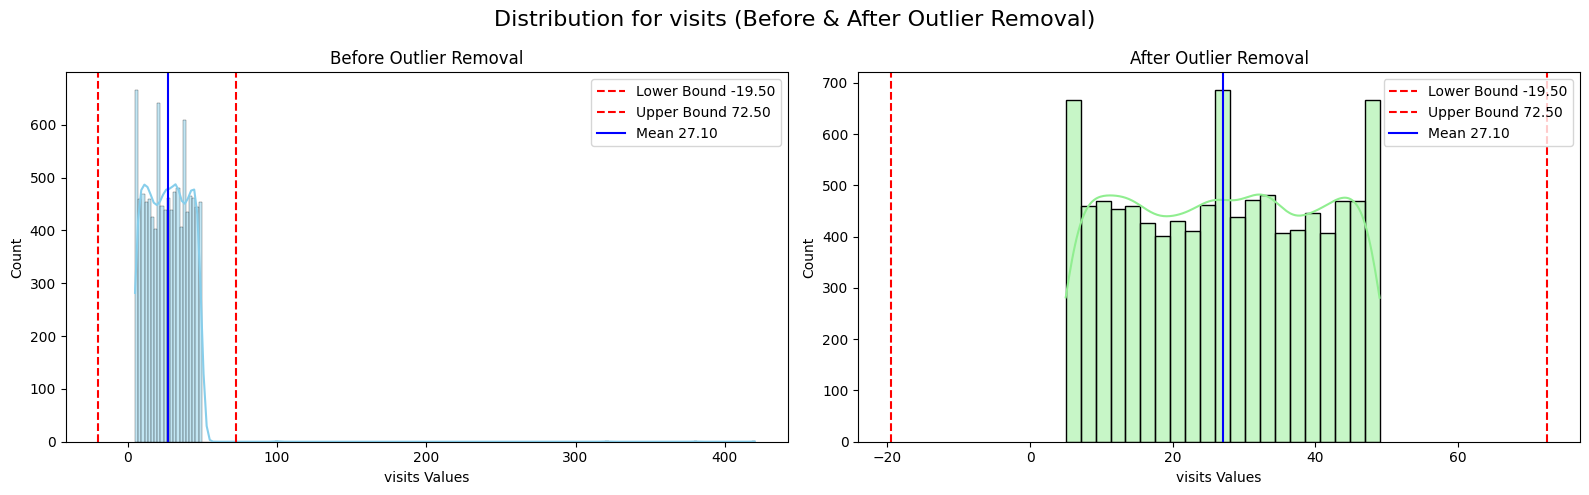

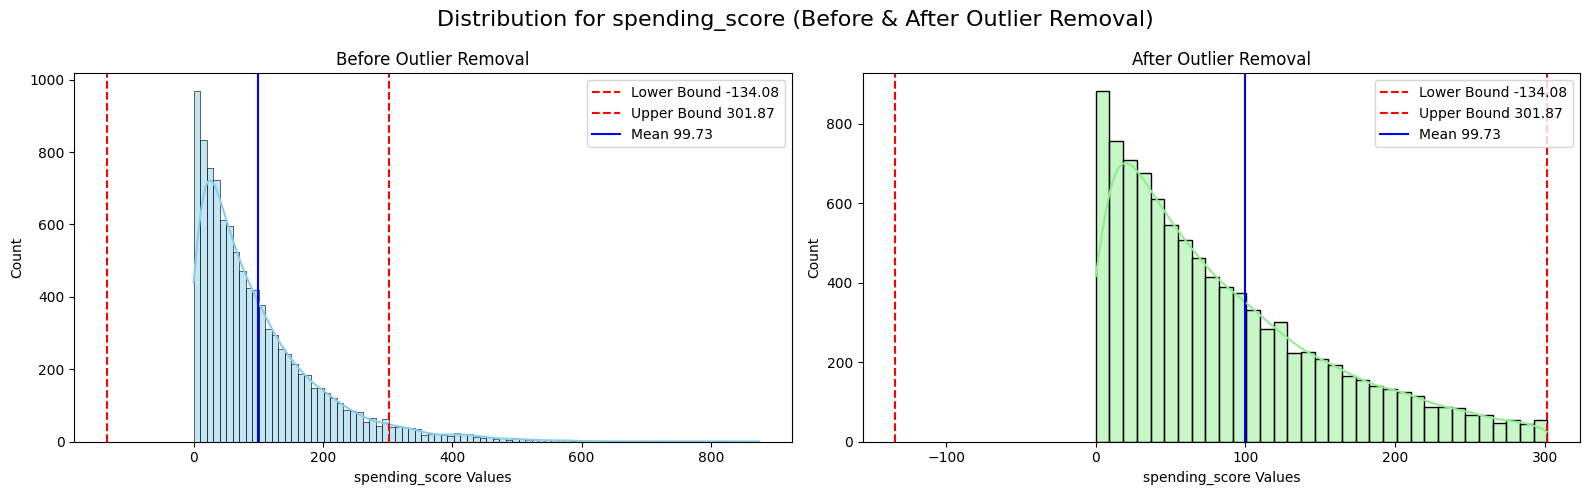

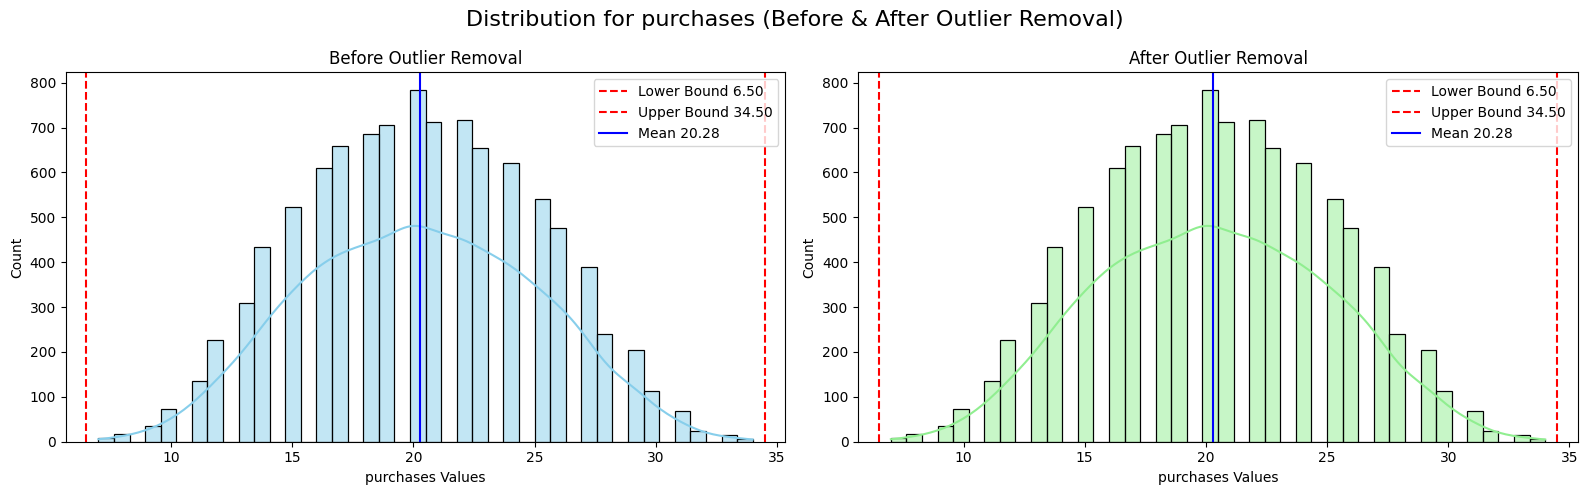

In [8]:
cols = df.columns
print(df.shape)

for col in cols:
    if np.issubdtype(df[col].dtype, np.number):  # Only numeric columns
        if df[col].dropna().empty:
            print(f"Skipping {col} (no data after previous filtering).")
            continue

        # --- Calculate IQR for outliers ---
        Q1 = np.percentile(df[col], 25)
        Q3 = np.percentile(df[col], 75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        mean_val = df[col].mean()

        # --- Create figure ---
        fig, axes = plt.subplots(1, 2, figsize=(16, 5))
        fig.suptitle(f"Distribution for {col} (Before & After Outlier Removal)", fontsize=16)

        # --- BEFORE REMOVAL ---
        sns.histplot(df[col], kde=True, ax=axes[0], color="skyblue")
        axes[0].axvline(lower, color='red', linestyle='--', label=f'Lower Bound {lower:.2f}')
        axes[0].axvline(upper, color='red', linestyle='--', label=f'Upper Bound {upper:.2f}')
        axes[0].axvline(mean_val, color='blue', linestyle='-', label=f'Mean {mean_val:.2f}')
        axes[0].set_title("Before Outlier Removal")
        axes[0].set_xlabel(f"{col} Values")
        axes[0].legend()

        # Remove outliers for next plot
        filtered_df = df[(df[col] > lower) & (df[col] < upper)]

        # --- AFTER REMOVAL ---
        sns.histplot(filtered_df[col], kde=True, ax=axes[1], color="lightgreen")
        axes[1].axvline(lower, color='red', linestyle='--', label=f'Lower Bound {lower:.2f}')
        axes[1].axvline(upper, color='red', linestyle='--', label=f'Upper Bound {upper:.2f}')
        axes[1].axvline(mean_val, color='blue', linestyle='-', label=f'Mean {mean_val:.2f}')
        axes[1].set_title("After Outlier Removal")
        axes[1].set_xlabel(f"{col} Values")
        axes[1].legend()

        plt.tight_layout()
        plt.show()


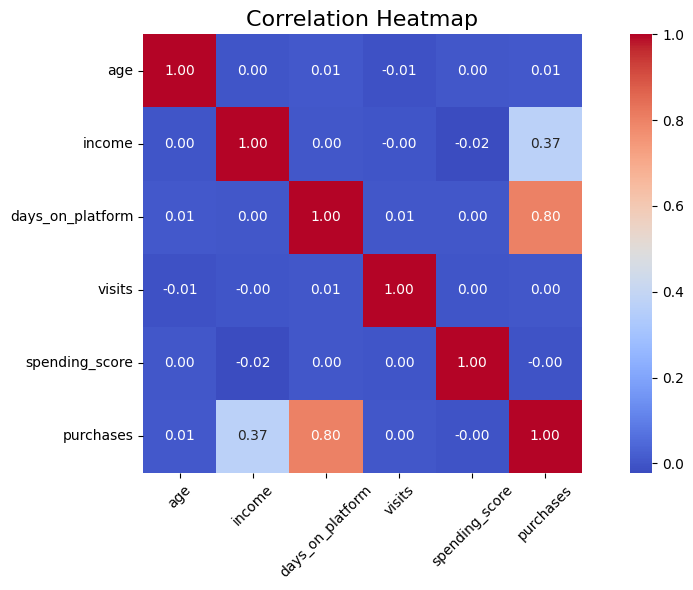

In [52]:
numeric_df = df.select_dtypes(include=np.number).drop(['id'], axis=1)

# Calculate correlation matrix
corr_matrix = numeric_df.corr()

# Create a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)

plt.title("Correlation Heatmap", fontsize=16)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

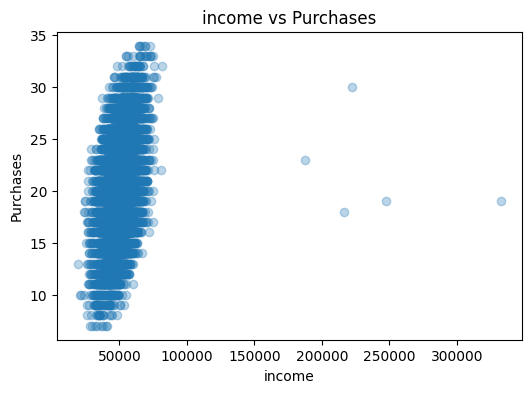

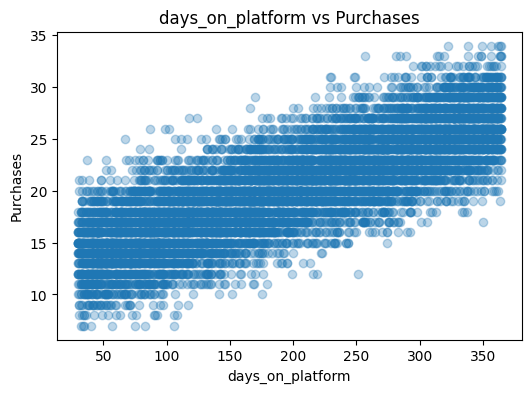

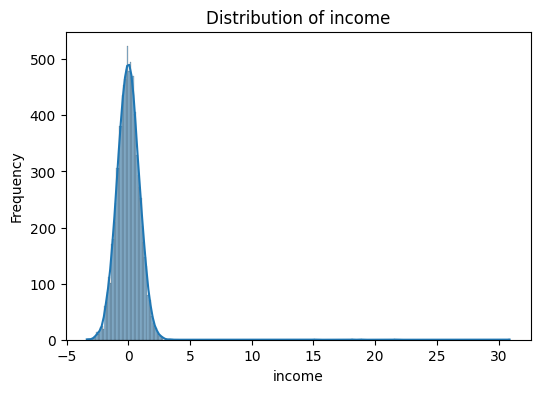

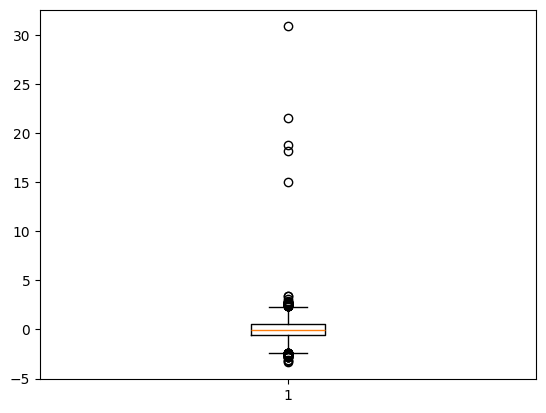

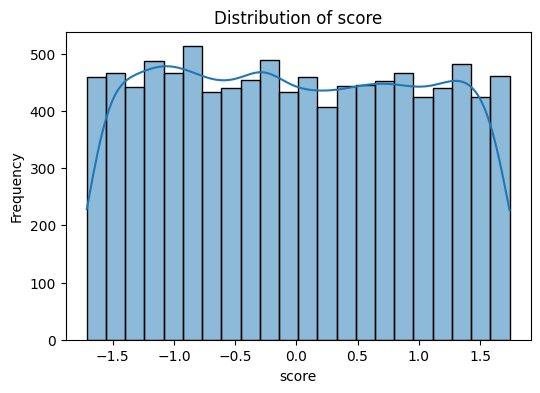

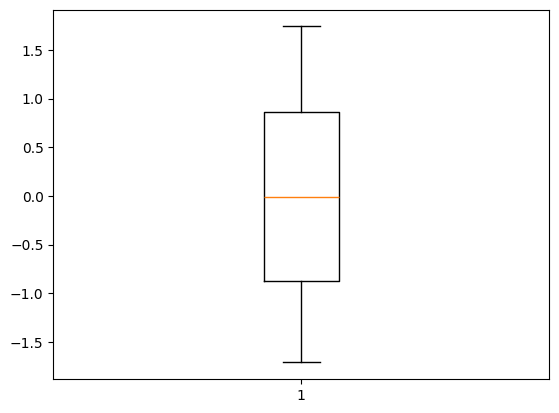

In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
# Split X and y
X = df.drop(columns=["purchases", "id",'visits','spending_score','age'])
y = df["purchases"]
# print(X)

for col in X.columns:
    plt.figure(figsize=(6, 4))
    plt.scatter(X[col], y, alpha=0.3)
    plt.xlabel(col)
    plt.ylabel("Purchases")
    plt.title(f"{col} vs Purchases")
    plt.show()



# Scale only X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
a_scale=pd.DataFrame(X_scaled,columns=['income','score'])
for col in a_scale.columns:
    plt.figure(figsize=(6, 4))
    sns.histplot(a_scale[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
    plt.boxplot(a_scale[col])

    
# # sns.histplot()
# # Train/test split
# X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# # Train linear regression
# model = LinearRegression()
# model.fit(X_train, y_train)

# print("Model Coefficients:", model.coef_)
# print("Intercept:", model.intercept_)
# print("Score on Test Set:", model.score(X_test, y_test))

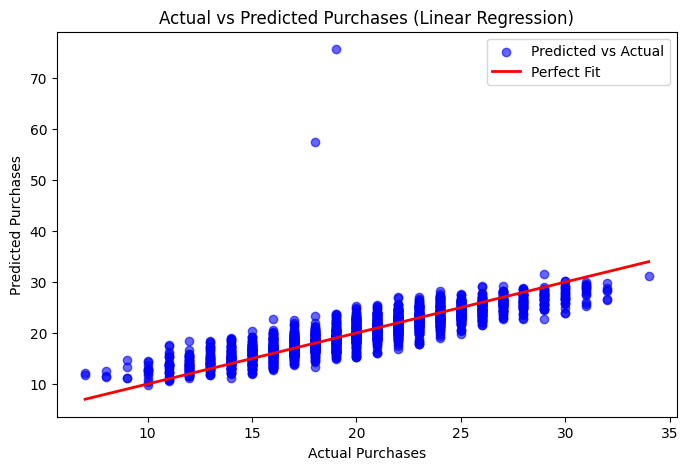

In [58]:
y_pred = model.predict(X_test)

# Scatter plot of Actual vs Predicted
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color="blue", alpha=0.6, label="Predicted vs Actual")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", lw=2, label="Perfect Fit")
plt.xlabel("Actual Purchases")
plt.ylabel("Predicted Purchases")
plt.title("Actual vs Predicted Purchases (Linear Regression)")
plt.legend()
plt.show()

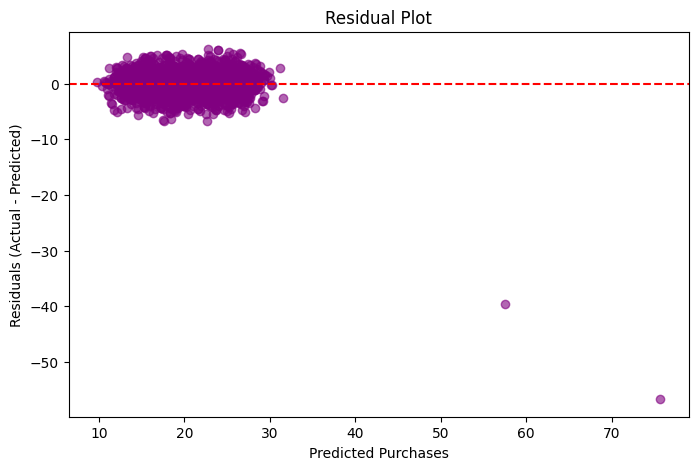

In [59]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, color="purple", alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Purchases")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()


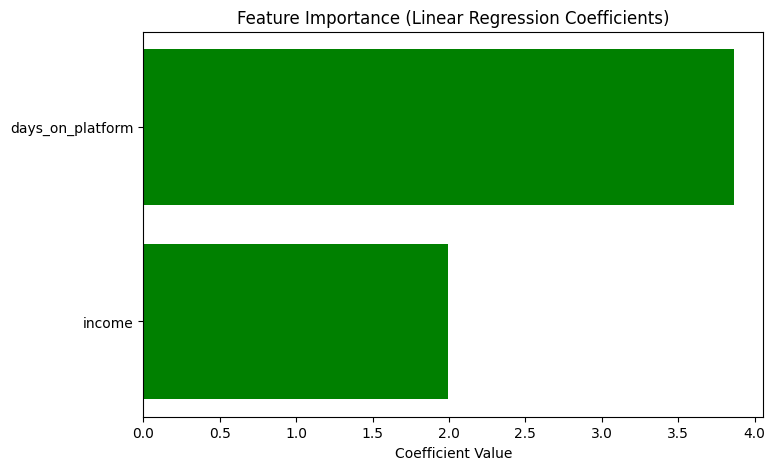

In [60]:
feature_names = X.columns  # original feature names
coef_df = pd.DataFrame({"Feature": feature_names, "Coefficient": model.coef_})

plt.figure(figsize=(8, 5))
plt.barh(coef_df["Feature"], coef_df["Coefficient"], color="green")
plt.xlabel("Coefficient Value")
plt.title("Feature Importance (Linear Regression Coefficients)")
plt.show()

In [63]:

y=model.predict([[5000,50]])


[10178.4976363]
